In [ ]:
## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [ ]:

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*



In [3]:
amz = df.copy()

In [4]:
amz.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [5]:
amz.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [9]:
amz.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [10]:
amz['category'].unique()

array(['Hi-Fi Speakers', 'CD, Disc & Tape Players', 'Wearable Technology',
       'Light Bulbs', 'Bathroom Lighting',
       'Heating, Cooling & Air Quality', 'Coffee & Espresso Machines',
       'Lab & Scientific Products', 'Smart Speakers',
       'Motorbike Clothing', 'Motorbike Accessories',
       'Motorbike Batteries', 'Motorbike Boots & Luggage',
       'Motorbike Chassis', 'Handmade Home & Kitchen Products',
       'Hardware', 'Storage & Home Organisation',
       'Fireplaces, Stoves & Accessories', 'PC Gaming Accessories',
       'USB Gadgets', 'Blank Media Cases & Wallets', 'Car & Motorbike',
       'Boys', 'Sports & Outdoors', 'Microphones', 'String Instruments',
       'Karaoke Equipment', 'PA & Stage',
       'General Music-Making Accessories', 'Wind Instruments',
       'Handmade Gifts', 'Fragrances', 'Calendars & Personal Organisers',
       'Furniture & Lighting', 'Computer Printers', 'Ski Goggles',
       'Snowboards', 'Skiing Poles', 'Downhill Ski Boots',
       'Hiki

In [11]:
amz['isBestSeller'].unique()

array([False,  True])

In [16]:
crosstab1 = pd.crosstab(amz['category'], amz['isBestSeller'])
crosstab1

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [19]:
# Adding a new column for total products per category
crosstab1['Total'] = crosstab1[True] + crosstab1[False]

# Calculating proportion of best-sellers in each category
crosstab1['BestSeller_Rate'] = (crosstab1[True] / crosstab1['Total']) * 100

# Sort descending by best-seller proportion
crosstab1_sorted = crosstab1.sort_values(by='BestSeller_Rate', ascending=False)

crosstab1_sorted.head(10)


isBestSeller,False,True,Total,BestSeller_Rate
category,,,,
Grocery,9008,556,9564,5.813467
Smart Home Security & Lighting,98,6,104,5.769231
Health & Personal Care,9017,552,9569,5.768628
Mobile Phone Accessories,248,11,259,4.247104
Power & Hand Tools,8353,306,8659,3.533895
"Billiard, Snooker & Pool",241,8,249,3.212851
Pet Supplies,9152,285,9437,3.020028
Home Brewing & Wine Making,239,7,246,2.845528
Wind Instruments,243,7,250,2.800000


The table avobe displays the top 10 category products where Best-Sellers are Most Prevalent.  Among them, Grocery, Smart Home Security & Lighting and Health & Personal Care, are the  three categories that have the highest proportion of best-sellers, with around 5.7–5.8% of products achieving best-seller status.

In [ ]:
2. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

---


C:\Users\jgest\AppData\Local\Temp\ipykernel_18028\3782165529.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


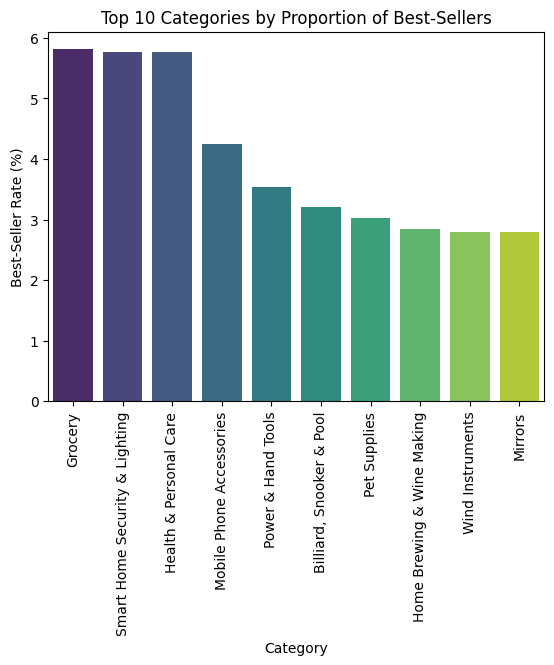

In [23]:
sns.barplot(
    data=crosstab1_sorted.reset_index().head(10),
    x='category',
    y='BestSeller_Rate',
    palette='viridis'
)
plt.title("Top 10 Categories by Proportion of Best-Sellers")
plt.xlabel("Category")
plt.ylabel("Best-Seller Rate (%)")
plt.xticks(rotation=90)
plt.show()

In [ ]:

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


In [24]:
amz.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [28]:
round(amz['price'].describe(),2)

count    2443651.00
mean          89.24
std          345.61
min            0.00
25%            9.99
50%           19.09
75%           45.99
max       100000.00
Name: price, dtype: float64

In [46]:
# IQR = Q3 - q1

Q3 = amz['price'].quantile(0.75)
Q1 = amz['price'].quantile(0.25)

IQR = Q3 -Q1

IQR

36.0

In [42]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound)
print(upper_bound)

-44.01
99.99000000000001


In [48]:
amz_no_outliers = amz[(amz['price'] >= lower_bound) & (amz['price'] <= upper_bound)]

In [50]:
amz_no_outliers.shape

(2115963, 9)

In [56]:
round(amz_no_outliers['price'].describe(),2)

count    2115963.00
mean          23.41
std           20.51
min            0.00
25%            9.13
50%           15.99
75%           29.99
max           99.99
Name: price, dtype: float64

In [ ]:

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.


In [58]:
top20_categories = amz_no_outliers['category'].value_counts().head(20).index

amz_top20 = amz_no_outliers[amz_no_outliers['category'].isin(top20_categories)]

C:\Users\jgest\AppData\Local\Temp\ipykernel_18028\2822644476.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=amz_top20, x="category", y="price", palette="viridis")


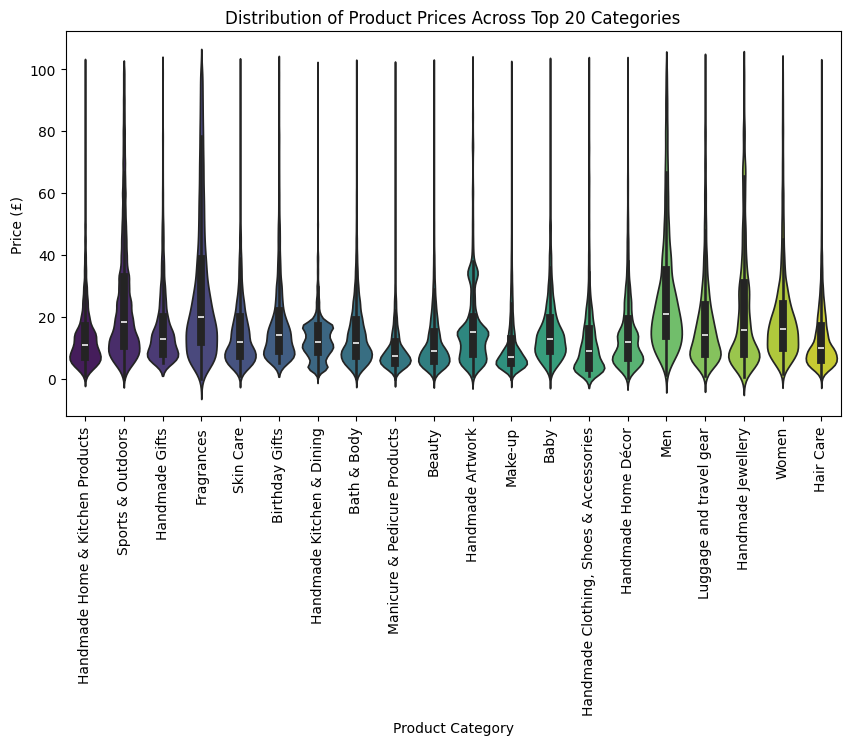

In [64]:
plt.figure(figsize=(10,5))
sns.violinplot(data=amz_top20, x="category", y="price", palette="viridis")

plt.xticks(rotation=90)
plt.title('Distribution of Product Prices Across Top 20 Categories')
plt.xlabel('Product Category')
plt.ylabel('Price (£)')
plt.show()

In [68]:
median_price = amz_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_price.head(1)

category
Desktop PCs    74.0
Name: price, dtype: float64

Desktop PCs is the product category with the highest median

In [ ]:

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.


In [82]:
top10_categories = amz_no_outliers['category'].value_counts().head(10).index

amz_top10 = amz_no_outliers[amz_no_outliers['category'].isin(top10_categories)]

avg_price = amz_top10.groupby('category')['price'].mean().sort_values(ascending= False)

avg_price


category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

C:\Users\jgest\AppData\Local\Temp\ipykernel_18028\2163009622.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price.index, y=avg_price.values, palette='viridis')


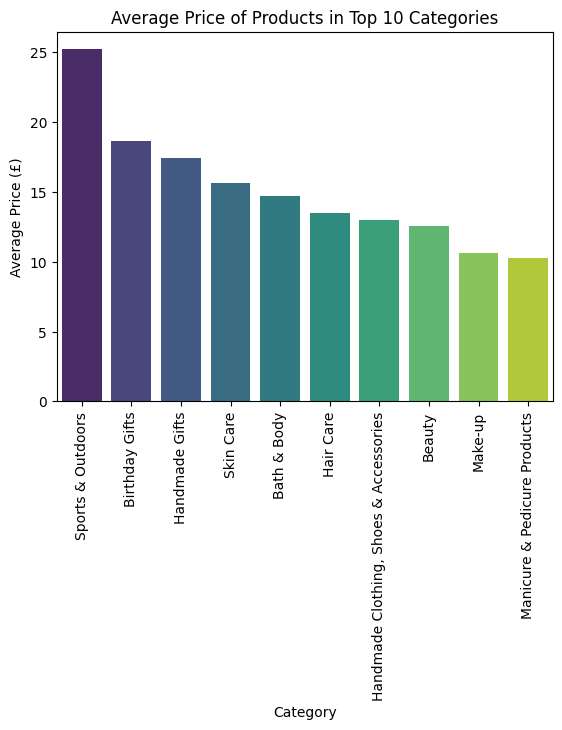

In [85]:
sns.barplot(x=avg_price.index, y=avg_price.values, palette='viridis')

plt.xticks(rotation=90)
plt.title('Average Price of Products in Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Average Price (£)')
plt.show()

Sports & Outdoors product categry commands the highest average price.

In [ ]:

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---


C:\Users\jgest\AppData\Local\Temp\ipykernel_18028\424095384.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot( data=amz_top10, x='category', y='stars', palette='viridis' )


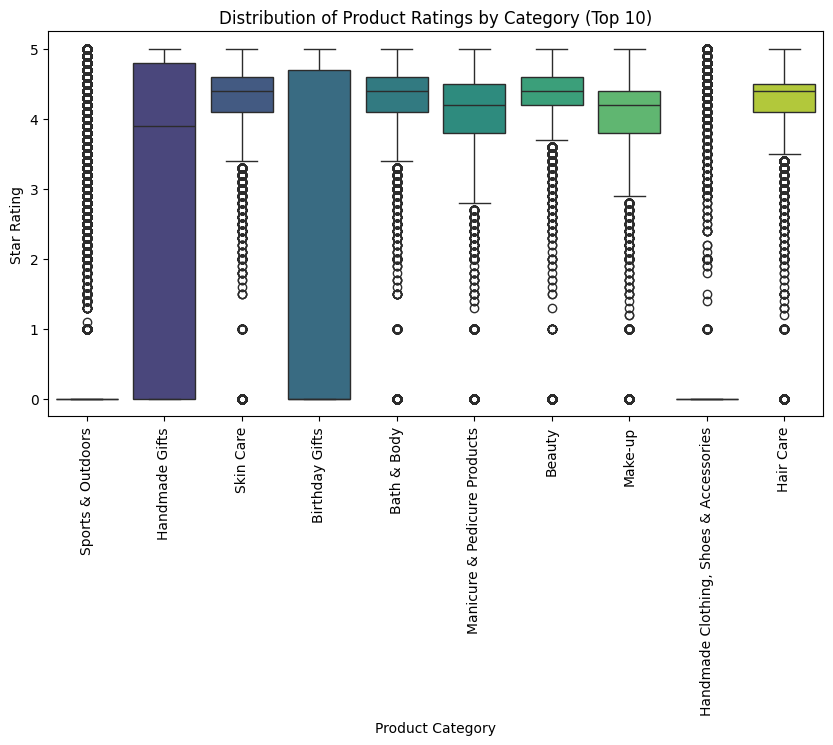

In [88]:
plt.figure(figsize=(10,5))
sns.boxplot( data=amz_top10, x='category', y='stars', palette='viridis' )

plt.title("Distribution of Product Ratings by Category (Top 10)")
plt.xlabel("Product Category")
plt.ylabel("Star Rating")
plt.xticks(rotation=90)
plt.show()

In [94]:
median_ratings = amz_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_ratings.head(1)

category
Computer Memory    4.7
Name: stars, dtype: float64

Computer Memory product category tends to recive the highests median rating from customers.

In [ ]:

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	


In [97]:
corr = amz['stars'].corr(amz['price'])
corr

-0.12490673262148384

The correlation coefficient indicates a very weak negative relationship between product price and customer rating.

In [ ]:
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

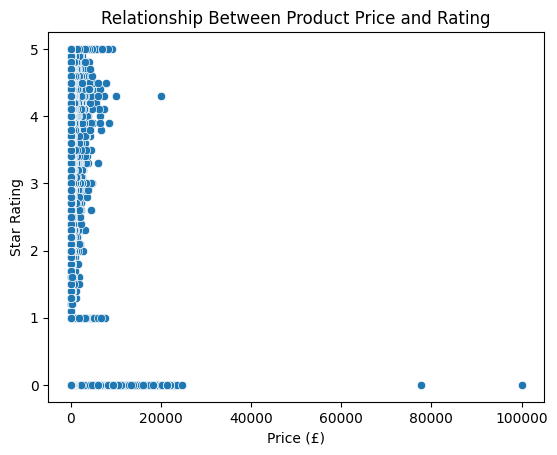

In [105]:
sns.scatterplot(data=amz, x='price', y='stars')
plt.title("Relationship Between Product Price and Rating")
plt.xlabel("Price (£)")
plt.ylabel("Star Rating")
plt.show()

There is no strong relationship between price and rating. The points are widely scattered, showing no clear trend (neither upward nor downward). Most points are concentrated near the left side (low price) of the graph. As price increases, the number of products drops sharply. If anything, there’s a slight negative pattern — a few high-priced items have lower ratings, which supports the small negative correlation.

In [107]:
num = amz.select_dtypes(include="number")
num.head()

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0


In [108]:
num.corr()

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


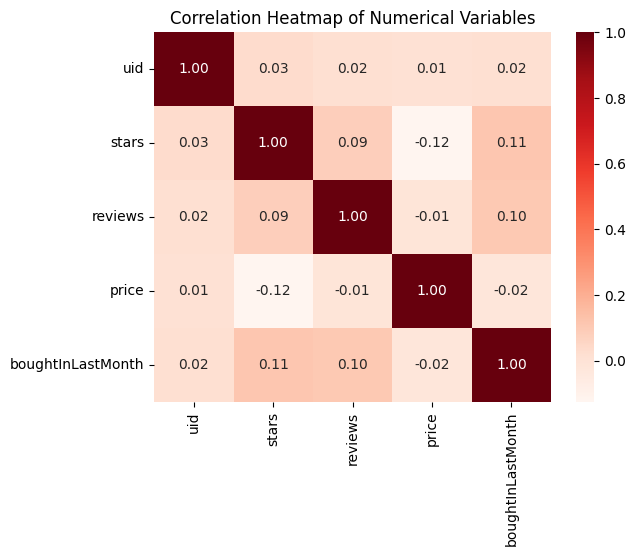

In [112]:
correlation_matrix = num.corr()

sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Reds")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

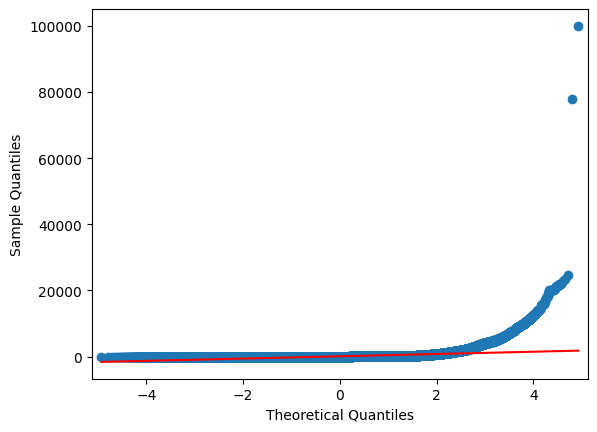

In [113]:
import statsmodels.api as sm

sm.qqplot(amz['price'], line='s');
plt.show()

The QQ plot of product prices shows a clear deviation from normality, with data points curving upward in the upper quantiles.
This pattern indicates a positively skewed distribution, driven by a small number of extremely high-priced products.